# Proyecto

Primero cargamos los datos y las librerias para usar

In [77]:
#install.packages("ggplot2")
#install.packages("dplyr")
#install.packages("lubridate")

library(ggplot2)

library(dplyr)
library(lubridate)
library(ggplot2)

In [78]:
df <- read.csv(file='data/hour.csv', head=TRUE, sep=',')

df[0:5,]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
1,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0,3,13,16
2,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0,8,32,40
3,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0,5,27,32
4,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0,3,10,13
5,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0,0,1,1


Por comodidad y formato voy a tener la variable de la fecha en una sola columna.

In [79]:
df$dteday <- paste( #combinar columnas
    df$dteday,
    df$hr,
    sep = " "
)

df$dteday <- as.POSIXct(x = df$dteday, format = '%Y-%m-%d %H') #transformarlos a variables tipo time

df[c("yr", "mnth", "hr", "cnt")] <- NULL #elimino variables que no sirven

df[0:5,]

,instant,dteday,season,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered
,<int>,<dttm>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
1,1,2011-01-01 00:00:00,1,0,6,0,1,0.24,0.2879,0.81,0,3,13
2,2,2011-01-01 01:00:00,1,0,6,0,1,0.22,0.2727,0.80,0,8,32
3,3,2011-01-01 02:00:00,1,0,6,0,1,0.22,0.2727,0.80,0,5,27
4,4,2011-01-01 03:00:00,1,0,6,0,1,0.24,0.2879,0.75,0,3,10
5,5,2011-01-01 04:00:00,1,0,6,0,1,0.24,0.2879,0.75,0,0,1


graficamos para veisualizar como se conportan las variables a predecir a travez del tiempo

In [80]:
df_diario <- df %>%
    group_by(dteday = floor_date(dteday, unit = "day")) %>%
    summarise(
        casual = mean(casual, na.rm = TRUE),
        registered = mean(registered, na.rm = TRUE)
    )

fecha_min <- as.Date("2011-01-01")
fecha_max <- as.Date("2011-02-01")

df_diario <- df_diario %>% filter(dteday >= fecha_min, dteday <= fecha_max)
df_diario[0:5,]

dteday,casual,registered
<dttm>,<dbl>,<dbl>
2011-01-01,13.791667,27.25000
2011-01-02,5.695652,29.13043
2011-01-03,5.454545,55.86364
2011-01-04,4.695652,63.21739
2011-01-05,3.565217,66.00000


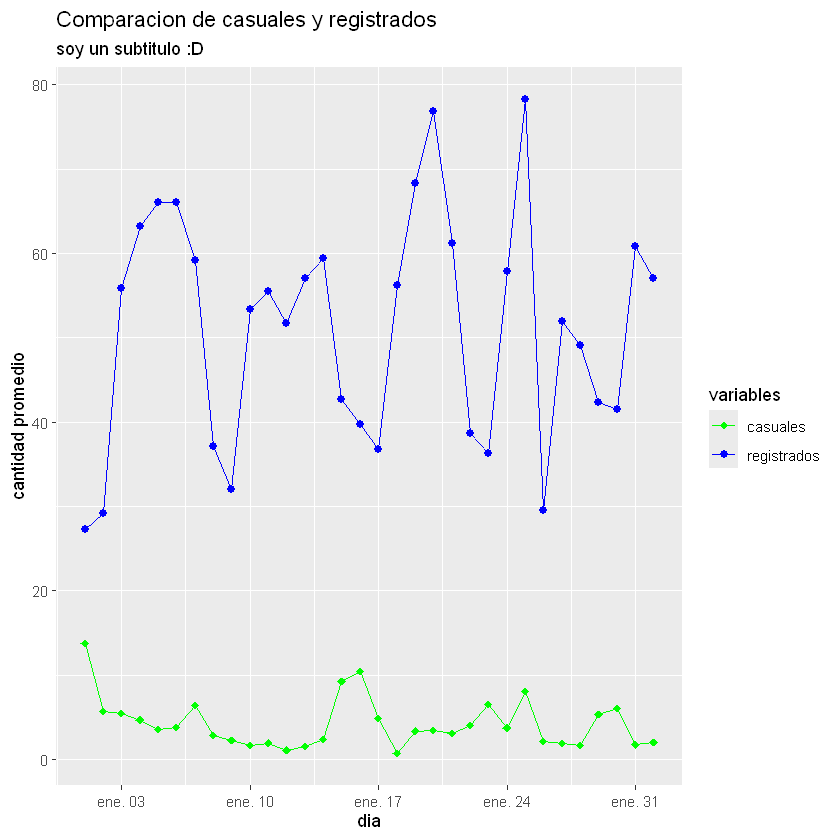

In [81]:
ggplot(data=df_diario, aes(x = dteday)) + 

    geom_line(aes(y = casual, color='casuales')) + 
    geom_point(aes(y = casual, color='casuales'), size = 2, shape=18)+

    geom_line(aes(y = registered, color='registrados')) +
    geom_point(aes(y = registered, color='registrados'), size = 2, shape = 16)+

    scale_color_manual(
        values = c(
            'casuales' = 'green',
            'registrados' = 'blue'
        )
    ) +

    labs(
        title='Comparacion de casuales y registrados',
        subtitle= 'soy un subtitulo :D',
        x='dia',
        y='cantidad promedio',
        color='variables'
    )

In [82]:
df_mensual <- df %>%
    filter(!is.na(dteday)) %>%
    group_by(dteday = floor_date(dteday, unit = "month")) %>%
    summarise(
        casual = mean(casual, na.rm = TRUE),
        registered = mean(registered, na.rm = TRUE)
    )

df_mensual[0:5,]


dteday,casual,registered
<dttm>,<dbl>,<dbl>
2011-01-01,4.466570,51.04070
2011-02-01,9.617874,64.67334
2011-03-01,17.569863,70.16301
2011-04-01,31.079277,100.86787
2011-05-01,41.733871,140.82124


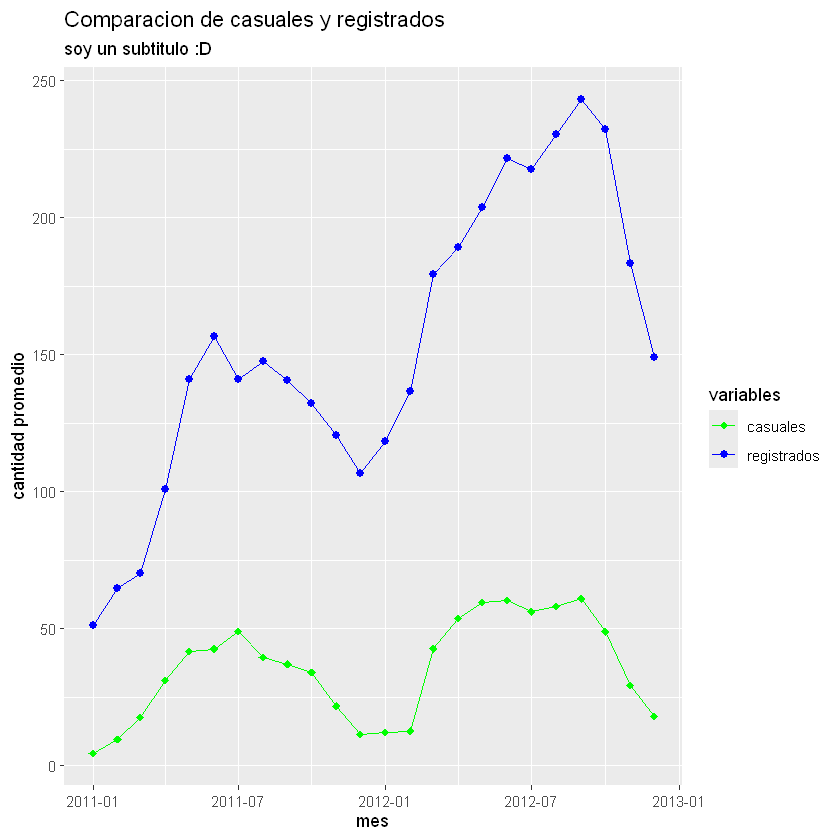

In [83]:
ggplot(data=df_mensual, aes(x = dteday)) + 

    geom_line(aes(y = casual, color='casuales')) + 
    geom_point(aes(y = casual, color='casuales'), size = 2, shape=18)+

    geom_line(aes(y = registered, color='registrados')) +
    geom_point(aes(y = registered, color='registrados'), size = 2, shape = 16)+

    scale_color_manual(
        values = c(
            'casuales' = 'green',
            'registrados' = 'blue'
        )
    ) +

    labs(
        title='Comparacion de casuales y registrados',
        subtitle= 'soy un subtitulo :D',
        x='mes',
        y='cantidad promedio',
        color='variables'
    )